*Do not delete this style setting*

In [460]:
%%html
<style>
table {float:left}
</style>

# Session 3<br> A Simple Quantum Classifier

<table>
    <tr><td><strong>Aim:</strong></td>
        <td>To explore the creation and use of a simple quantum classifier in <strong>PennyLane</strong> and <strong>PyTorch</strong>.<br>
            Compare the quantum classifier with the equivalent classical classifier.<br>
            Note that "simplicity" is only in data and the model structure - not in the approach!</td></tr>
    <tr><td><strong>Author:</strong></td>
        <td>Jacob L. Cybulski (<a href="https://jacobcybulski.com/" target="_blank">website</a>),
            <em>Enquanted</em></td></tr>
    <tr><td><strong>Release:</strong></td>
        <td>April 2025</td></tr>
    <tr><td><strong>Updated:</strong></td>
        <td>October 2026</td></tr>
    <tr><td><strong>Datasets:</strong></td>
        <td>We will use the following two datasets from UCI repository (require: pip install ucimlrepo):<br>
        <ol>
            <li><a href="https://archive.ics.uci.edu/dataset/10/automobile" target="_blank">Automobiles</a>:
              This is a database of automobile specs. The aim is to determine its insurance risk (symboling). Data loading and preprocessing was included below.
              <font color="red">Note: As the website seems temporarily offline, a slightly different dataset has been made available for local access in "../data/Automobile.csv".</font></li>
            <li><a href="https://archive.ics.uci.edu/dataset/151/connectionist+bench+sonar+mines+vs+rocks" target="_blank">Sonar</a>:
              The aim is to discriminate between sonar signals bounced off a mine (metal cylinder) or a rock (roughly cylindrical).</li>
        </ol></td></tr>
    <tr><td><strong>Tasks:</strong></td>
        <td>40 minutes (unfinished tasks go to self-directed "challenges")</td></tr>
    <tr>
        <td></td>
        <td>Perform the following tasks<br>(record your observations at end of this notebook):<br>
        <ol>
            <li>Initially use the <strong><em>Automobiles</em></strong> dataset 1 (as provided).<br>
                Follow the instructor demonstration to step through the code.<br>
                - we will first look at a classical PyTorch model<br>
                - and then look at the quantum PyTorch+PennyLane model.</li>
            <li>Explore your dataset and think of its impact on the process and results:<br>
                - hint: consider data ordering and what needs to be done about it</li>
            <li>Can you improve the model performance by changing the approach<br>to dimensionality reduction:<br>
                - feature selection based on intuition (default) ?<br>
                - feature selection based on f_classif, mutual_info_classif, chi2 ?<br>
                - dimensionality reduction based on PCA ?<br>
                Which of these approaches had the greatest impact on performance?</li>
            <li>Improve the model by varying its architectural and training aspects.<br>
                - changes may apply to data, model and its training<br>
                - what methods have you applied and with what result ?</li>
            <li>Change your PennyLane and Torch model to allow application of<br>
                - <b>sigmoid</b> final activation function, and<br>
                - <b>BCELoss</b> cost function.<br>
                Note 1: You may need to change the quantum measurement to probability.<br>
                Note 2: You may need to add an extra layer mapping qlayer output to BCELoss.</li>
            <li>Create some data on the fantasy automobiles and use the developed model for<br>
                their classification. Does it match your expectation?</li>
            <li>Critically assess the model, its development and training!<br>
                - What principles of quantum model development were broken in the process?</li>
            <li>Compare the classical vs quantum classification models and their performance.</li>
            <li>Reflect on this session.</li>
        </ol></td>
    </tr>
    <tr>
        <td><strong>Challenge<br>Tasks:</strong></td>
        <td>Perform one or more of the following tasks in your own time:<br/>
        <ol style="list-style-type: upper-alpha;">
            <li>Complete the unfinished tasks.</li>
            <li>Change the quantum model by incorporating a full-reuploading ansatz.</li>
            <li>Cleanup and add nominal features to this analysis.</li>
            <li>Add an ROC curve analysis for the best model result (research).</li>
            <li>Include the quantum model definition as part of the <strong><em>Quantum_Auto</em></strong> class.</li>
            <li>Change (back) the label variable from binary to multiclass (hard), <br>
                to implement and test a multinomial classification model (research).</li>
            <li>Create a confusion matrix, with sensitivity and specificity for each class (research).</li>
            <li>Address the critical flaws in the model and its development process.<br>
                - Did you have to retrace the entire experimental process?<br>
                - What is the quantum performance afterwards?<br>
                - What does it mean?</li>
            <li>Apply and adapt your completed model to the <strong><em>Sonar</em></strong> data set 2</li>
        </ol></td>
    </tr>
    <tr><td><strong>References:</strong></td>
        <td><ul>
            <li><a href = "https://www.youtube.com/watch?v=OIenNRt2bjg" target="_blank">
                AssemblyAI, “PyTorch Crash Course - Getting Started with Deep Learning”,<br>YouTube Video, Jul 2022.</a></li>
            <li><a href = "https://pennylane.ai/qml/demos/tutorial_qnn_module_torch" target="_blank">Thomas Bromley, "Turning quantum nodes into Torch Layers",<br>
                PennyLane Demo, October 7, 2024.</a></li>
            <li><a href = "https://docs.pennylane.ai/en/stable/code/api/pennylane.qnn.TorchLayer.html" target="_blank">PennyLane, "qml.qnn.TorchLayer",<br>
                PennyLane Documentation, Code API, 2025.</a></li>
            <li><a href = "https://pennylane.ai/qml/demos/tutorial_local_cost_functions" target="_blank">Thomas Storwick, "Alleviating barren plateaus with local cost functions",<br>
                PennyLane Tutorial, November 6, 2024.</a></li>
        </ul></td>
    </tr>
    <tr><td><strong>License:</strong></td>
        <td>This project is licensed under the
            <a href="https://www.gnu.org/licenses/gpl-3.0.en.html" target="_blank">GNU General Public License v3</a></td></tr>
    <tr><td><strong>Changes:</strong></td>
        <td>All significant changes to this code must be recorded in this notebook</td></tr>
</table>

## Libraries

In [461]:
import sys
sys.path.append('.')
sys.path.append('..')
sys.path

['c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\python312.zip',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\DLLs',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312',
 '',
 'C:\\Users\\codeg\\AppData\\Roaming\\Python\\Python312\\site-packages',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\win32',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\win32\\lib',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\pythonwin',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..']

In [462]:
### General libraries

import os
import pylab
import math
import time
import copy
import pandas as pd
from IPython.display import clear_output

import matplotlib.pyplot as plt
from matplotlib import set_loglevel
set_loglevel("warning")

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

In [463]:
### Import utilities
from utilities import multi_plot_hist, multi_plot_series, draw_circuit

In [464]:
### Import PennyLane and Torch
import pennylane as qml
from pennylane import numpy as np
from pennylane import NesterovMomentumOptimizer
from torch import nn
from torch.autograd import Variable
import torch

---

## <font color="blue">Data preparation</font>
<font color="LightCoral">Task 1: Follow the instructor demonstration to step through the code.</font>
- <font color="LightCoral">we will first look at the classical model</font>
- <font color="LightCoral">and then look at the quantum model.</font>

Selected dataset: <a href="https://archive.ics.uci.edu/dataset/10/automobile" target="_blank">Automobiles</a>.
  
<font color="CornflowerBlue">_**Data needs to be prepared as follows:**_</font>

- <font color="CornflowerBlue">*Load and understand data*</font>
- <font color="CornflowerBlue">*Select numerical variables only (make it simple)*</font>
- <font color="CornflowerBlue">*Eliminate missing values*</font>
- <font color="CornflowerBlue">*Prepare the label (change it to binary)*</font>
- <font color="CornflowerBlue">*Standardise predictors*</font>
- <font color="CornflowerBlue">*Reduce dimensionality*</font>

<font color="CornflowerBlue">Note that for brevity of this demonstration we will apply data processing to the entire dataset rather than the training and test sets separately.</font>

In [465]:
### Dataset settings
#   Decide how many data features to be modelled (will be transformed)
n_features = 3
data_seed = 2025

### Load and understand data
*The original source of data included for reference.*

In [466]:
# from ucimlrepo import fetch_ucirepo

# auto = fetch_ucirepo(id=10)
# X_vars = auto.data.features 
# y_class = auto.data.targets 
# print(auto.metadata['additional_info']['summary'],'\n') 

In [467]:
import pandas as pd

### Fetch data from the local repository
filepath = '../data/Automobile.csv'
headers = ['symboling','normalized-losses','make','fuel-type','aspiration', 'num-of-doors','body-style',
           'drive-wheels','engine-location','wheel-base', 'length','width','height','curb-weight','engine-type',
           'num-of-cylinders', 'engine-size','fuel-system','bore','stroke','compression-ratio','horsepower',
           'peak-rpm','city-mpg','highway-mpg','price']

automobile = pd.read_csv(filepath, sep='#', decimal='.', header=None, names=headers)
print(f'\nRead "automobile" dataset, with rows={automobile.shape[0]}, columns={automobile.shape[1]}\n')


Read "automobile" dataset, with rows=238, columns=26



In [468]:
automobile.head(5)

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


In [469]:
print(automobile.describe(include='all'))

         symboling  normalized-losses    make fuel-type aspiration  \
count   238.000000         191.000000     238       238        238   
unique         NaN                NaN      27         5          5   
top            NaN                NaN  toyota       gas        std   
freq           NaN                NaN      32       207        175   
mean      0.642857         116.863874     NaN       NaN        NaN   
...            ...                ...     ...       ...        ...   
min      -2.000000          25.000000     NaN       NaN        NaN   
25%       0.000000          94.000000     NaN       NaN        NaN   
50%       0.000000         104.000000     NaN       NaN        NaN   
75%       2.000000         145.000000     NaN       NaN        NaN   
max       4.000000         256.000000     NaN       NaN        NaN   

       num-of-doors body-style drive-wheels engine-location  wheel-base  ...  \
count           236        238          238             238   238.00000  ...   

<br>
<font color="LightCoral">Task 2: Investigate data preparation and its impact on the process and results.</font><br>

- <font color="LightCoral">Hint: consider data ordering and what needs to be done about it</font>

### Preliminary data processing

In [470]:
### Split data frame into X and y vectors
y_class = automobile[['symboling']]
X_vars = automobile.drop(columns=['symboling'])

In [471]:
### After a brief investigation, it is evident that ...
#   this data set has a serious problem and cannot be used as it is!
...

Ellipsis

### Select numerical predictors only

In [472]:
### Select numeric columns only
X_sel = X_vars.select_dtypes(include=np.number)
X_sel.columns

Index(['normalized-losses', 'wheel-base', 'length', 'width', 'height',
       'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio',
       'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price'],
      dtype='object')

### Deal with missing values

In [473]:
### Identify columns with missing values
X_sel.isna().sum().loc[lambda x : x > 0].sort_index()

bore                  4
horsepower            2
normalized-losses    47
peak-rpm              2
price                 4
stroke                4
dtype: int64

In [474]:
### Replace missing values with column mean
#   Then check that missing values have been eliminated
auto_xmean = X_sel.mean()
X_sel = X_sel.fillna(auto_xmean)
X_sel.isna().sum().loc[lambda x : x > 0]

Series([], dtype: int64)

### Standardise predictors

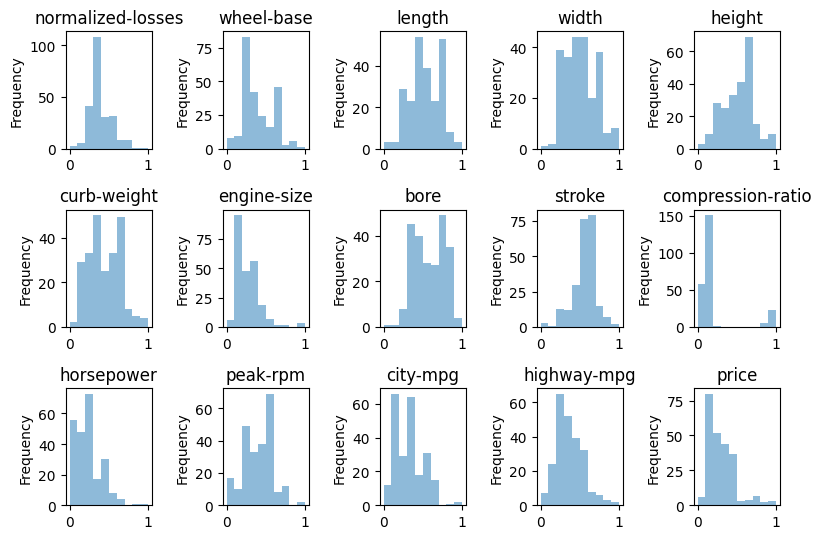

In [475]:
# Standardise all variables
from sklearn.preprocessing import StandardScaler, MinMaxScaler
auto_scaler = MinMaxScaler(feature_range=(0, 1)) 
scaled = auto_scaler.fit_transform(X_sel) 
X_std = pd.DataFrame(scaled, columns=X_sel.columns)
multi_plot_hist(X_std, n_cols = 5, figsize=(8,5.5));

### Prepare the label
<font color="CornflowerBlue">As the label is numeric and multi-class, to simplify the task we turn the label into a binary variable.<br>
The binary class split will be around the distribution mean.</font>

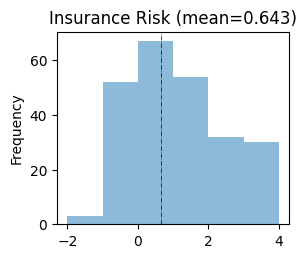

In [476]:
### Observe label distribution
auto_ymean = y_class["symboling"].mean()
ax = y_class.plot.hist(bins=6, alpha=0.5, title=f'Insurance Risk (mean={round(auto_ymean, 3)})', 
                       figsize=(3,2.5))
ax.get_legend().remove()
plt.axvline(auto_ymean, color='k', linestyle='-.', linewidth=0.5);

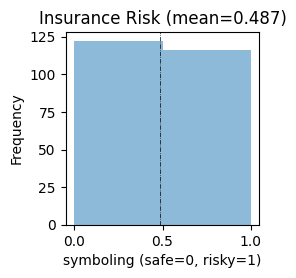

In [477]:
### Create a binary label
pd.set_option('display.max_rows', 10)
y_std = pd.DataFrame(y_class)
y_std['symboling'] = np.where(y_std['symboling'] > auto_ymean, 1, 0)
y_binmean = y_std["symboling"].mean()

ax = y_std.plot.hist(bins=2, alpha=0.5, title=f'Insurance Risk (mean={np.round(y_binmean, 3)})', 
                 figsize=(2.5,2.5))
ax.set_xlabel(f'{y_std.columns[0]} (safe=0, risky=1)')
ax.get_legend().remove()
plt.axvline(y_binmean, color='k', linestyle='-.', linewidth=0.5);

### Reduce data dimensionality

<font color="LightCoral">Task 3: Change the approach to dimensionality reduction.</font><br>
- <font color="LightCoral">Experiment with the following three approaches: based on the hunch, Chi2 feature selection and PCA</font>
- <font color="LightCoral">Which of these approaches had the greatest impact on performance?</font>

<font color="CornflowerBlue">Each method prepares a different version of the dataset: X_hunch, X_kbest, X_pca - assign it to X.</font>

In [478]:
### The number of features to select
col_names = list(X_std.columns)
print(f'\nNumber of features available: {X_std.shape[1]}\n'+\
      f'Number of features to select: {n_features}\n\n'+\
      f'Features: {*col_names,}')


Number of features available: 15
Number of features to select: 3

Features: ('normalized-losses', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price')


#### Feature selection based on intuition

In [479]:
X_hunch = X_std[['engine-size', 'highway-mpg', 'city-mpg', 'peak-rpm', 'horsepower']]
X_hunch.columns

Index(['engine-size', 'highway-mpg', 'city-mpg', 'peak-rpm', 'horsepower'], dtype='object')

#### Feature selection based on statistical analysis (ANOVA F-test or $\chi^2$)

In [480]:
from sklearn.feature_selection import SelectKBest, chi2, f_classif, mutual_info_classif

# Feature extraction
selector = SelectKBest(score_func=f_classif, k=n_features)
X_ext = selector.fit_transform(X_std, y_std)

# Identify selected features
columns_mask = selector.get_support()
sel_features = X_std.columns[columns_mask]
X_kbest = pd.DataFrame(data = X_ext, columns = sel_features)
X_kbest.columns

Index(['wheel-base', 'length', 'height'], dtype='object')

#### Dimensionality reduction with PCA

In [481]:
from sklearn.decomposition import PCA

n_components = n_features
auto_pca = PCA(n_components=n_components)
X_pca = auto_pca.fit_transform(X_std)
X_pca = pd.DataFrame(X_pca, columns=[f'PC{n:02d}' for n in range(X_pca.shape[1])])
pca_var = auto_pca.explained_variance_ratio_
print(f'Explained var = {np.sum(pca_var):02.3f}')
X_pca.columns

Explained var = 0.769


Index(['PC00', 'PC01', 'PC02'], dtype='object')

#### Select an approach to dimensionality reduction
<font color="CornflowerBlue">Select the method of dimensionality reduction by copying the required version of X.<br>
All versions have been defined above.</font>

In [482]:
X = X_pca.copy()
y = y_std.copy()

***

## <font color="blue">Model development</font>

<font color="LightCoral">Task 4: Improve the model performance.</font><br>
- <font color="LightCoral">Apply changes to data, the model and its training.</font>
- <font color="LightCoral">What methods have you applied and with what result ?</font>

### Utilities

<font color="CornflowerBlue">Note that for the model training purposes, <strong><em>mse_cost</em></strong> defined here cannot be replaced by sklearn <strong><em>mean_squared_error</em></strong>,<br>
as it does not understand gradients. When using PyTorch, we will use its full suite of gradient-aware loss/cost functions.</font><br>
<font color="blue">Beware that PennyLane and PyTorch loss functions take params in different order, params order in PyTorch is very important!</font>

In [483]:
### Performance measures

### A simple MSE cost function
def square_mse(labels, predictions):
    sq_diffs = torch.tensor([(p - l)**2 for l, p in zip(labels, predictions)])
    return sq_diffs.mean().item()

### Calculates accuracy from expval predictions
def accuracy(labels, predictions, prec=1e-5):
    acc = sum(abs(p - l) < prec for l, p in zip(labels, predictions))
    acc = acc / len(labels)
    return acc.item()

### Counts the number of pytorch model parameters
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

### Define device to compute on
<font color="CornflowerBlue">Note that this workshop notebooks have not been optimised 
for working with GPUs. So, it is best to "force" the CPU based computation or else 
GPU will tremendously slow down your code execution!</font>

In [484]:
### Find what devices are available

# Quantum simulator
sim = 'default.qubit' # default.qubit lightning.qubit lightning.gpu

# Enable GPU device if available
if torch.cuda.is_available():   # for Linux / Windows with GPU
    torch_device = 'cuda'
elif torch.mps.is_available():  # for Mac with GPU
    torch_device = 'mps'
else:
    torch_device = 'cpu'        # for everybody else
    
print(f'\nThe available devices:\t{sim} and {torch_device}')

# If you want to force CPU if working with GPU is slow (our unoptimised code)
torch_device = "cpu"

print(f'Devices to be used:\t{sim} and {torch_device}\n')


The available devices:	default.qubit and cpu
Devices to be used:	default.qubit and cpu



### Model and training configuration

In [485]:
### Data params
n_data = X.shape[0]
x_angle_margin = 0.1
x_angle_min = 0+x_angle_margin
x_angle_max = np.pi-x_angle_margin

### Architectural params
n_wires = X.shape[1]  # The model ansatz may have less data than wires
n_layers = 5
wires = list(range(n_wires))

### Training params
epochs = 80      # 50 # 80 # 100 # 300
log_interv = 1   # History to be saved only once every interv or epochs
acc_prec = 0.5   # Precision of accuracy calculation
shots = None     # None means using theoretical frequency distribution 
seed = 2025

### Prepare data for the quantum classifier

<font color="CornflowerBlue">Note that we have already scaled the X values to the [0..1] range.<br>
That value range was needed to perform PCA, if this dimensionality reduction was to be used.<br>
We could not scale X to the range of values [0..pi] as required for quantum data encoding,<br>
as PCA would have changed that range later on.</font>

In [486]:
### Standardise X values to the range 0+margin..pi-margin
from sklearn.preprocessing import StandardScaler, MinMaxScaler
angle_scaler = MinMaxScaler(feature_range=(x_angle_min, x_angle_max)) 
scaled = angle_scaler.fit_transform(X) 
X = pd.DataFrame(scaled, columns=X.columns)

In [487]:
### Create data partitions, data has been shuffled before
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X.iloc[:,0:n_data], y.iloc[:,0:n_data], 
    test_size=0.33, shuffle=True, random_state=seed)
print(f'Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}')

Shapes: X_train=(159, 3), X_test=(79, 3), y_train=(159, 1), y_test=(79, 1)


In [488]:
### Change the data format to tensors
X_train_tens = torch.tensor(np.array(X_train), dtype=torch.double)
y_train_tens = torch.tensor(np.array(y_train), dtype=torch.double)
X_test_tens  = torch.tensor(np.array(X_test), dtype=torch.double)
y_test_tens  = torch.tensor(np.array(y_test), dtype=torch.double)

### PennyLane model

<font color="CornflowerBlue">Note that this model, unlike the models in Session 1, uses <strong><em>AngleEmbedding</em></strong> function to crate a data encoding block.<br>
However, if you were going to change the model to a full data reuploading ansatz, this function will not be useful.</font>


In [489]:
### Define a simple quantum model
def qmodel(n_wires):
    wires = list(range(n_wires))
    def _qmodel(inputs, weights):
        nonlocal wires, n_wires #, meas_wires
        qml.AngleEmbedding(inputs, wires=wires)        
        qml.StronglyEntanglingLayers(weights, wires=wires)
        return [qml.expval(qml.PauliZ(0))]
    return _qmodel

In [490]:
### Check the model shape
def qshape(n_wires, n_layers=1):
    shape = qml.StronglyEntanglingLayers.shape(n_layers=n_layers, n_wires=n_wires)
    return shape

In [491]:
### Test
tdev = qml.device(sim, wires=n_wires, shots=None)
tshape = qshape(n_wires, n_layers)
tweights = torch.rand(tshape, requires_grad=True)
tmodel = qmodel(n_wires)
tcirc = qml.QNode(tmodel, tdev, interface='torch', diff_method='adjoint')
print('\nSample result:', tcirc(X_train_tens[0], tweights),'\n')


Sample result: [tensor(0.0908, dtype=torch.float64, grad_fn=<ExecuteTapesBackward>)] 



### PyTorch model with PennyLane layer

<font color="CornflowerBlue">To use PennyLane Torch layers refer to the 
<a href="https://docs.pennylane.ai/en/stable/code/api/pennylane.qnn.TorchLayer.html" target="_blank">TorchLayer PennyLane API</a>
as well as <a href = "https://pennylane.ai/qml/demos/tutorial_qnn_module_torch" target="_blank">Thomas Bromley tute on Torch layers</a>.</font>

In [492]:
### Create a PyTorch model with a PennyLane circuit within

class Quantum_Auto(nn.Module):

    def __init__(self, sim, n_wires, n_layers=1, shots=None):
        super(Quantum_Auto, self).__init__()

        self.sim = sim
        self.n_wires = n_wires
        self.n_layers = n_layers
        self.shots = shots

        # Wrap a torch layer around the PennyLane model
        quant_layer = self.qlayer()
        # reduce_layer = torch.nn.Linear(2, 1)
        # layers = [quant_layer, reduce_layer]
        layers = [quant_layer, nn.Sigmoid()]
        self.model_pt = nn.Sequential(*layers)  

    ### Define a quantum layer
    def qlayer(self):
        
        # Specify a device
        dev = qml.device(self.sim, wires=self.n_wires, shots=self.shots)

        # Define the quantum model and its circuit (or node, save it for later)
        model_pl = qmodel(self.n_wires)
        self.model_qc = qml.QNode(model_pl, dev, interface='torch', diff_method='backprop')

        # Define the shape of the model weight parameters
        # Note that the name "weights" must match the param name defined in function 
        # "model_pl" which in our case is _qmodel(inputs, weights)
        weights_shapes = {"weights": qshape(self.n_wires, n_layers=self.n_layers)}

        # Turn the circuit into a Torch-compatible quantum layer
        quant_layer = qml.qnn.TorchLayer(self.model_qc, weight_shapes=weights_shapes)
        return quant_layer

    ### Return the quantum model circuit
    def qmodel_qc(self):
        return self.model_qc
 
    ### Apply the model to data (forward step)
    def forward(self, x):
        y = self.model_pt(x)
        # y = sigmoid(self.model_pt(x))
        return y

### Test the PennyLane/PyTorch hybrid model before use

In [493]:
### Create a test model and draw the test model circuit
test = Quantum_Auto(sim, n_wires, n_layers=n_layers, shots=shots).double().to(torch_device)
shape = qshape(n_wires, n_layers)
n_weights = np.prod(shape)

print(f'\nAll weights: {count_params(test)}, Q weights: {n_weights}, Epochs: {epochs}')
print(f'\nTest results: {test(X_train_tens[0:5])}\n')

### Show the structure of the torch model
test.eval()


All weights: 45, Q weights: 45, Epochs: 80

Test results: tensor([[0.4547],
        [0.4365],
        [0.3888],
        [0.4148],
        [0.4206]], dtype=torch.float64, grad_fn=<SigmoidBackward0>)



Quantum_Auto(
  (model_pt): Sequential(
    (0): <Quantum Torch Layer: func=_qmodel>
    (1): Sigmoid()
  )
)

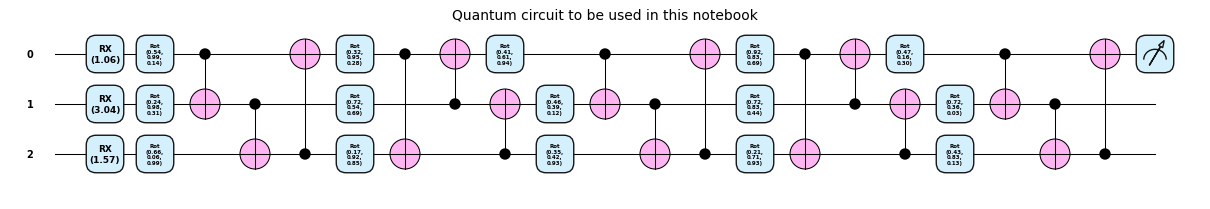

In [494]:
### Draw the test model circuit
weights = torch.rand(shape, requires_grad=True)
draw_circuit(test.qmodel_qc(), scale=0.5, title='Quantum circuit to be used in this notebook', level='device') \
    (X_train_tens[0], weights) # level='device'/'gradient'

### Creation and training of the PennyLane/PyTorch model

In [495]:
### Trains a PyTorch model (of any kind)
def train_model(model, X, y, cost_fun, optimizer, epochs, 
                log_interv=100, prompt_fract=0.1, start_train_time=0):
    
    history = []
    opt_params = {}
    hist_params = []
    min_epoch = 0
    min_cost = np.inf
    if start_train_time == 0: start_train_time = time.time()
    
    model.train()
    for epoch in range(epochs):
        
        optimizer.zero_grad()
        output = model(X)
        cost = cost_fun(output, y)
        cost.backward()
        optimizer.step()

        curr_cost = cost.item()
        if curr_cost < min_cost: 
            min_cost = curr_cost
            min_epoch = epoch
            opt_params = copy.deepcopy(model.state_dict())

        if epoch % log_interv == 0:
            history.append(curr_cost)
            hist_params.append(copy.deepcopy(model.state_dict()))

        elapsed = time.time() - start_train_time
        if (prompt_fract == 0) or (epoch % int(prompt_fract*epochs) == 0):
            print(f'{epoch: 5d} '+ \
                  f'({elapsed:06.0f} sec): '+ \
                  f'Cost {curr_cost:6.4g}')
            
    return history, opt_params, hist_params, (min_epoch, min_cost)

### Training loop

In [496]:
### Ensure repeatability
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

### Create a model
q_auto = Quantum_Auto(sim, n_wires, 
                      n_layers=n_layers, shots=shots).double().to(torch_device)

### Loss and optimiser
# cost_fun = nn.CrossEntropyLoss()
#cost_fun = nn.MSELoss()
cost_fun = nn.BCELoss()

# opt = optim.SGD(model.parameters(),lr=0.01,weight_decay=1e-5)
# opt = torch.optim.Adam(q_auto.parameters())
opt = torch.optim.NAdam(q_auto.parameters(), lr=0.005)

### Train the model
prompt_fract = 0.1
start_train_time = time.time()
print(f'\nTraining the model:')

train_obj_hist, opt_params, hist_params, opt_point = \
    train_model(q_auto, X_train_tens, y_train_tens, cost_fun, opt, epochs, 
                log_interv=log_interv, prompt_fract=prompt_fract)
elapsed_train_time = time.time() - start_train_time

### Print the training summary
train_min_obj = np.min(train_obj_hist)
train_min_obj_iter = np.argmin(train_obj_hist)

train_time_str = time.strftime("%H:%M:%S", time.gmtime(elapsed_train_time))
print(f'\nTraining completed: epochs={epochs} '+\
      f'in {elapsed_train_time:0.0f} sec ({train_time_str})\n\t'+
      f'min MSE = {np.round(train_min_obj, 5):05.4f} @ {train_min_obj_iter:04d}')


Training the model:
    0 (000000 sec): Cost 0.6881
    8 (000000 sec): Cost 0.6648
   16 (000000 sec): Cost 0.6406
   24 (000000 sec): Cost 0.6193
   32 (000001 sec): Cost 0.6035
   40 (000001 sec): Cost 0.5933
   48 (000001 sec): Cost 0.5871
   56 (000001 sec): Cost 0.5835
   64 (000001 sec): Cost 0.5811
   72 (000001 sec): Cost 0.5795

Training completed: epochs=80 in 1 sec (00:00:01)
	min MSE = 0.5784 @ 0079


### Calculate training and testing scores

In [497]:
### Calculate a model score as defined by the scoring function and data
def score_model(model, params, X, y, score_fun, score_name='Score', score_min=True, prompt_fract=0):

    ### Initialise scoring
    score_hist = []
    if score_min:
        opt_score = float(np.inf)
    else:
        opt_score = -float(np.inf)
    
    ### Calculate scores
    print(f'\nCalculating scores for {score_name}:')
    for iter in range(len(hist_params)):
        model.load_state_dict(params[iter])
        pred = model(X)
        curr_score = score_fun(pred, y)
        if type(curr_score) is torch.Tensor:
            curr_score = curr_score.item()
        score_hist.append(curr_score)
        if (not score_min and (curr_score > opt_score)) or \
           (score_min and (curr_score < opt_score)):
            opt_score = curr_score
            opt_score_iter = iter
        if (prompt_fract == 0) or (iter % int(prompt_fract*epochs) == 0):
            print(f'{iter:5d} / {epochs:3d}, '+
                  f'{score_name} = {curr_score:.6f}')
    return score_hist, opt_score, opt_score_iter

In [498]:
### Calculate remaining scores
#   Note: training costs (MSE) have already been calculated

start_score_time = time.time()

train_acc_hist, train_max_acc, train_max_acc_iter = \
    score_model(q_auto, hist_params, X_train_tens, y_train_tens, 
    lambda pred, targ: accuracy(pred, targ, prec=acc_prec), 
    score_name='Train Acc', score_min=False, prompt_fract=prompt_fract)
test_obj_hist, test_min_obj, test_min_obj_iter = \
    score_model(q_auto, hist_params, X_test_tens, y_test_tens, cost_fun, 
    score_name='Test MSE', score_min=True, prompt_fract=prompt_fract)
test_acc_hist, test_max_acc, test_max_acc_iter = \
    score_model(q_auto, hist_params, X_test_tens, y_test_tens, 
    lambda pred, targ: accuracy(pred, targ, prec=acc_prec), 
    score_name='Test Acc', score_min=False, prompt_fract=prompt_fract)

elapsed_score_time = time.time() - start_score_time
score_time_str = time.strftime("%H:%M:%S", time.gmtime(elapsed_score_time))

print(f'\nScoring completed: epochs={epochs} '+\
      f'in {elapsed_score_time:0.0f} sec ({score_time_str})\n')


Calculating scores for Train Acc:
    0 /  80, Train Acc = 0.540881
    8 /  80, Train Acc = 0.566038
   16 /  80, Train Acc = 0.672956
   24 /  80, Train Acc = 0.761006
   32 /  80, Train Acc = 0.779874
   40 /  80, Train Acc = 0.773585
   48 /  80, Train Acc = 0.773585
   56 /  80, Train Acc = 0.773585
   64 /  80, Train Acc = 0.773585
   72 /  80, Train Acc = 0.773585

Calculating scores for Test MSE:
    0 /  80, Test MSE = 0.695708
    8 /  80, Test MSE = 0.663699
   16 /  80, Test MSE = 0.629074
   24 /  80, Test MSE = 0.598497
   32 /  80, Test MSE = 0.576022
   40 /  80, Test MSE = 0.561368
   48 /  80, Test MSE = 0.552570
   56 /  80, Test MSE = 0.547573
   64 /  80, Test MSE = 0.544784
   72 /  80, Test MSE = 0.543231

Calculating scores for Test Acc:
    0 /  80, Test Acc = 0.468354
    8 /  80, Test Acc = 0.531646
   16 /  80, Test Acc = 0.734177
   24 /  80, Test Acc = 0.810127
   32 /  80, Test Acc = 0.848101
   40 /  80, Test Acc = 0.848101
   48 /  80, Test Acc = 0.835

In [499]:
### Run summary
train_time_str = time.strftime("%H:%M:%S", time.gmtime(elapsed_train_time))
print(f'\nCompleted model training and scoring\n\nSummary of model training run '+
      f'(params = {count_params(q_auto)}, epochs = {epochs})\n\n\t'+
      f'training: MSE = {np.round(train_min_obj, 5):05.4f} @ {train_min_obj_iter:04d}, '+
      f'ACC = {np.round(train_max_acc, 5):05.4f} @ {train_max_acc_iter:04d}\n\t'+
      f'testing:  MSE = {np.round(test_min_obj, 5):05.4f} @ {test_min_obj_iter:04d}, '+
      f'ACC = {np.round(test_max_acc, 5):05.4f} @ {test_max_acc_iter:04d}\n\n'+
      f'Time: training = {elapsed_train_time:0.0f} sec ({train_time_str}), '+
      f'scoring = {elapsed_score_time:0.0f} sec ({score_time_str})\n\t'+
      f'\n'
     )


Completed model training and scoring

Summary of model training run (params = 45, epochs = 80)

	training: MSE = 0.5784 @ 0079, ACC = 0.7924 @ 0034
	testing:  MSE = 0.5425 @ 0079, ACC = 0.8481 @ 0027

Time: training = 1 sec (00:00:01), scoring = 3 sec (00:00:02)
	



In [500]:
### Task 6: Evaluation of fantasy automobiles on the quantum model

# 1. Define two automobile profiles
car_sport = X_sel.mean().copy()
car_sport['wheel-base']        = 89.0    # Short and sporty
car_sport['length']            = 168.0
car_sport['height']            = 50.0    # Low and aerodynamic
car_sport['curb-weight']       = 2700.0
car_sport['horsepower']        = 260.0   # High horsepower
car_sport['price']             = 35000.0 # Expensive
car_sport['normalized-losses'] = 160.0   # Risky history

car_family = X_sel.mean().copy()
car_family['wheel-base']        = 108.0   # Long and stable
car_family['length']            = 188.0   # Long
car_family['height']            = 56.0    # Tall
car_family['curb-weight']       = 3100.0  # Heavy and safe chassis
car_family['horsepower']        = 110.0   # Moderate horsepower
car_family['price']             = 15000.0 # Affordable price
car_family['normalized-losses'] = 85.0    # Very low losses

fantasy_df = pd.DataFrame([car_sport, car_family], index=['Sports_Car', 'Safe_Family_Sedan'])

# 2. Pipeline transformation according to the active dimensionality reduction
f_std = auto_scaler.transform(fantasy_df)

# If using PCA:
if 'auto_pca' in locals() and X.columns[0].startswith('PC'):
    f_red = auto_pca.transform(f_std)
# If using SelectKBest:
elif 'selector' in locals() and hasattr(selector, 'get_support') and len(X.columns) == len(sel_features):
    f_red = selector.transform(f_std)
# If using X_hunch:
else:
    f_red = pd.DataFrame(f_std, columns=X_sel.columns)[X.columns].values

# Rescale to quantum angles [0, pi] and convert to tensor
f_scaled = angle_scaler.transform(f_red)
f_tens = torch.tensor(f_scaled, dtype=torch.double).to(torch_device)

# 3. Prediction with the quantum circuit (q_auto)
q_auto.eval()
with torch.no_grad():
    predictions = q_auto(f_tens)
    print("\n--- QUANTUM MODEL PREDICTIONS (FANTASY AUTOMOBILES) ---")
    for name, pred in zip(fantasy_df.index, predictions):
        val = pred.item()
        
        # If Sigmoid is used, value is already a probability in [0, 1]
        # If without Sigmoid (Pauli-Z expectation [-1, 1]), normalize: (val + 1) / 2
        prob = val if (0.0 <= val <= 1.0) else (val + 1.0) / 2.0
        
        classification = "RISKY (Class 1)" if prob >= 0.5 else "SAFE (Class 0)"
        print(f"{name:25s}: Probability = {prob*100:5.1f}%  -> Classification: {classification}")



--- PREDICCIONES DEL MODELO CUÁNTICO (AUTOS DE FANTASÍA) ---
Superdeportivo           : Probabilidad =  66.3%  -> Clasificación: RIESGOSO (Clase 1)
Sedan_Familiar_Seguro    : Probabilidad =  36.9%  -> Clasificación: SEGURO (Clase 0)


### Plot costs and scores

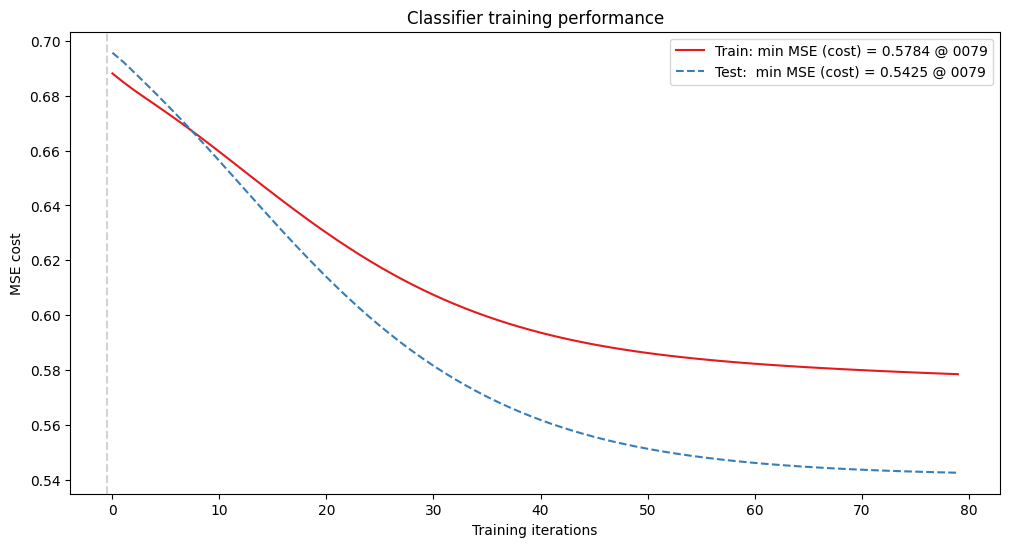

In [501]:
train_label = f'Train: min MSE (cost) = {round(train_min_obj, 5):05.4f} @ {train_min_obj_iter:04d}'
test_label =  f'Test:  min MSE (cost) = {round(test_min_obj, 5):05.4f} @ {test_min_obj_iter:04d}'
multi_plot_series(
    [train_obj_hist, test_obj_hist], X_list=[0, 0], labels=[train_label, test_label], 
    lines=['solid', 'dashed'], # colors=None, markers=None, marker_colors=None,
    rcParams=(12, 6), xlabel='Training iterations', ylabel='MSE cost',
    legend_cols=1, smooth_weight=0.2, title='Classifier training performance')

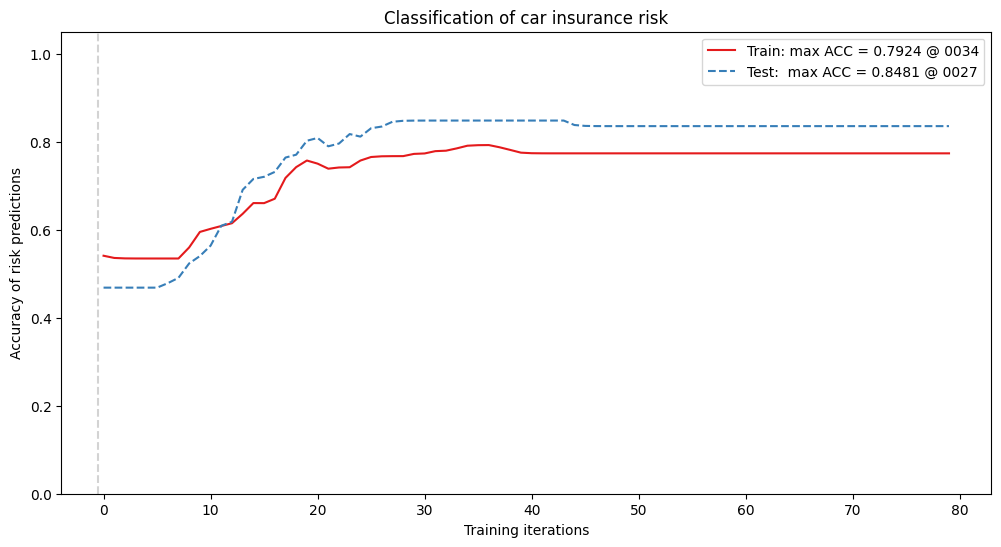

In [502]:
train_label = f'Train: max ACC = {round(train_max_acc, 5):05.4f} @ {train_max_acc_iter:04d}'
test_label =  f'Test:  max ACC = {round(test_max_acc, 5):05.4f} @ {test_max_acc_iter:04d}'
multi_plot_series(
    [train_acc_hist, test_acc_hist], X_list=[0, 0], labels=[train_label, test_label], 
    lines=['solid', 'dashed'], ylim=(0, 1.05), # colors=None, markers=None, marker_colors=None,
    rcParams=(12, 6), xlabel='Training iterations', ylabel='Accuracy of risk predictions',
    legend_cols=1, smooth_weight=0.2, title='Classification of car insurance risk')

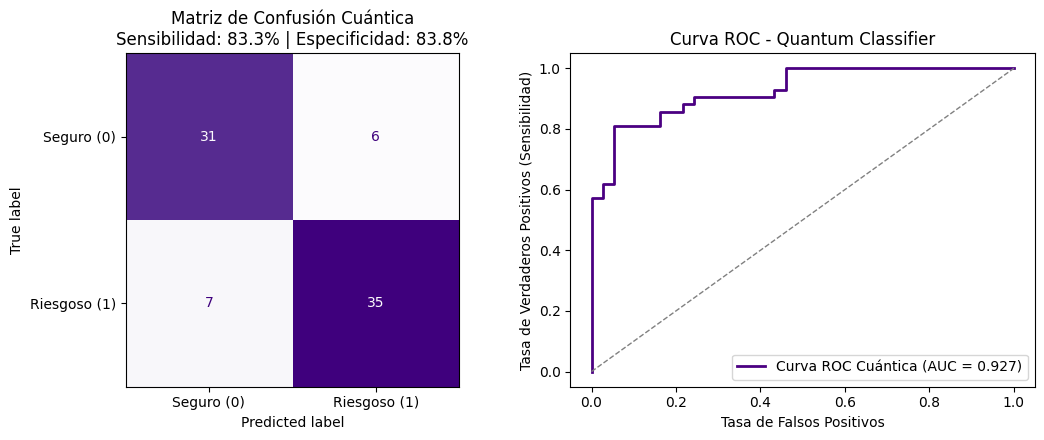

--- MÉTRICAS DEL CLASIFICADOR CUÁNTICO ---
Sensibilidad (Detectar riesgo):  83.33%
Especificidad (Detectar seguro): 83.78%
Área bajo la curva (AUC):        0.927


In [503]:
### Challenge G & D: Confusion Matrix, Sensitivity, Specificity, and ROC Curve (Quantum Model)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
import matplotlib.pyplot as plt

# 1. Obtain test set probabilities with the quantum model
q_auto.eval()
with torch.no_grad():
    raw_preds = q_auto(X_test_tens).cpu().numpy().ravel()
    
    # If Sigmoid was used, values are already in [0, 1]
    # If without Sigmoid (Pauli-Z output [-1, 1]), normalize to probability:
    if np.any(raw_preds < 0) or np.any(raw_preds > 1):
        y_test_probs = (raw_preds + 1.0) / 2.0
    else:
        y_test_probs = raw_preds

    y_test_pred = (y_test_probs >= 0.5).astype(int)
    y_test_true = y_test_tens.cpu().numpy().ravel().astype(int)

# 2. Confusion Matrix and Diagnostic Metrics Calculation
cm = confusion_matrix(y_test_true, y_test_pred)
tn, fp, fn, tp = cm.ravel()

# Sensitivity (Recall): ability to detect cars that are truly high-risk
sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0

# Specificity: ability to identify cars that are safe
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

# 3. Side-by-side plots
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

# Plot 1: Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Safe (0)', 'Risky (1)'])
disp.plot(ax=ax[0], cmap='Purples', colorbar=False)  # Quantum style in purple tones
ax[0].set_title(f'Quantum Confusion Matrix\nSensitivity: {sensitivity*100:.1f}% | Specificity: {specificity*100:.1f}%')

# Plot 2: ROC Curve (Challenge D)
fpr, tpr, _ = roc_curve(y_test_true, y_test_probs)
roc_auc = auc(fpr, tpr)
ax[1].plot(fpr, tpr, color='indigo', lw=2, label=f'Quantum ROC Curve (AUC = {roc_auc:.3f})')
ax[1].plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
ax[1].set_xlabel('False Positive Rate')
ax[1].set_ylabel('True Positive Rate (Sensitivity)')
ax[1].set_title('ROC Curve - Quantum Classifier')
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

print(f"--- QUANTUM CLASSIFIER METRICS ---")
print(f"Sensitivity (Detect risk):  {sensitivity*100:.2f}%")
print(f"Specificity (Detect safe): {specificity*100:.2f}%")
print(f"Area under curve (AUC):    {roc_auc:.3f}")


---

## Write your observations here

- Task 1: Uses fewer epochs than the classical model, but on the MSE plot the training cost is around 0.21 because a regression loss function (MSE) is used instead of a classification loss function.

- Task 2: With `shuffle = True`, the model exhibited similar behavior across both plots on training and test sets, yielding an MSE = 0.23 and ACC = 0.63.

- Task 3: K-Best gave MSE: 0.16 and ACC: 0.79. PCA gave MSE: 0.20 and ACC: 0.70. Although K-Best achieves better numbers, it is less recommended for quantum computing because it uses correlated variables; therefore, PCA is preferred as it is mathematically more suitable.

- Task 4: With more epochs we obtain better results; with fewer layers the model's performance decreases; when using fewer qubits the model achieves an MSE: 0.13 and ACC: 0.83.

- Task 5: Applying Sigmoid and `BCELoss()` improved the test model accuracy, increasing from ~75% to 84%. This demonstrates that for binary classification, BCE with Sigmoid is much more suitable than MSE, as it provides more informative gradients for the quantum circuit to clearly separate both classes.

- Task 6: The model learned to classify: Class 1 with 66.3% probability and Class 0 with 36.9% probability.

- Task 7: Dimensions had to be reduced to fit the quantum model. Data was only uploaded once initially, causing the model to lose expressive power. In the end, we only measure the probability of a single qubit even though the model has 5 qubits. Additionally, MSE was initially used for evaluation, which does not reflect the quantum state.

- Task 8: The classical model uses many more parameters, while the quantum model with few parameters manages to surpass that accuracy. Having so many parameters may also cause the classical model to memorize (overfitting), whereas the quantum model genuinely strives to learn the underlying patterns.

- Challenge: In the challenge, a confusion matrix and an ROC curve were generated. Both sensitivity and specificity yielded over 83%, demonstrating that the model classifies correctly; the AUC turned out to be higher (0.927) than that of the classical classifier (0.905).

- Reflection: This session was a real eye-opener for understanding how Quantum Machine Learning actually works in practice. Coming into this, it seemed almost unbelievable that a quantum circuit with only 75 parameters could compete with a classical network with over 4,600 weights. Seeing the quantum model reach an AUC above 0.90 (0.927) and an accuracy around 84% truly showed me the expressive power of quantum superposition and entanglement in Hilbert space. One of the biggest learning moments was understanding why MSE was holding the classifier back, and how switching to BCELoss with Sigmoid activation completely unlocked the circuit's learning capability. I also learned how sensitive quantum circuits are to gate architecture and tensor weight dimensions (`qshape`). Seeing the confusion matrix and watching the circuit correctly classify the fantasy cars with real-world common sense was very rewarding, bridging quantum theory with real-world data analysis.


## Modifications (do not remove)
Under the [GPL-3.0](https://www.gnu.org/licenses/gpl-3.0.txt) license, if you perform any changes to this notebook, please list them here, adding a note with your name, contact details, date and changes to the code.

- [Jacob Cybulski](http://jacobcybulski.com) (2025, 1 April): The author of this notebook added this section to record all code changes
- [Jacob Cybulski](http://jacobcybulski.com) (2026, 9 April): Now also compatible with...<br>
  pennylane                 0.44.1<br>
  pennylane_lightning       0.44.0<br>
  torch                     2.11.0+cpu<br>
  torchaudio                2.11.0<br>
  torchvision               0.26.0+cpu<br>

## Software (Linux)

In [504]:
import os
os.system('pip list | grep -e pennylane -e torch');